<a href="https://colab.research.google.com/github/olyadiya/DL_2026/blob/main/rnn_hw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RNN-классификатор


In [ ]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib pandas

In [ ]:
import re
import time
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm.auto import tqdm

In [ ]:
SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 1. Данные

In [ ]:
dataset = load_dataset("fancyzhx/ag_news")

all_train = list(zip(dataset['train']['label'], dataset['train']['text']))
test_data = list(zip(dataset['test']['label'],  dataset['test']['text']))

rng = random.Random(SEED)
perm = list(range(len(all_train)))
rng.shuffle(perm)

N_VAL = 12_000
val_data   = [all_train[i] for i in perm[:N_VAL]]
train_data = [all_train[i] for i in perm[N_VAL:]]

CLASS_NAMES = ['World', 'Sports', 'Business', 'Sci/Tech']

print(f"train: {len(train_data)} | val: {len(val_data)} | test: {len(test_data)}")
print("Распределение меток (train):", Counter(l for l, _ in train_data))

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

train: 108000 | val: 12000 | test: 7600
Распределение меток (train): Counter({1: 27072, 3: 27035, 2: 26993, 0: 26900})


## 2. Токенизация и словарь

In [ ]:
def tokenizer(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())


def tokenize_split(data):
    tokens = [tokenizer(text) for _, text in data]
    labels = np.array([label for label, _ in data])
    return tokens, labels


train_tokens, train_labels = tokenize_split(train_data)
val_tokens,   val_labels   = tokenize_split(val_data)
test_tokens,  test_labels  = tokenize_split(test_data)

train_counter = Counter(tok for toks in train_tokens for tok in toks)

In [ ]:
PAD_IDX, UNK_IDX = 0, 1


def build_vocab(counter, min_freq):
    vocab = {'<pad>': PAD_IDX, '<unk>': UNK_IDX}
    frequent = [t for t, c in counter.items() if c >= min_freq]
    frequent.sort(key=lambda t: (-counter[t], t))
    vocab.update({t: i for i, t in enumerate(frequent, start=2)})
    return vocab


for mf in (2, 5, 10):
    print(f"MIN_FREQ={mf:>2} -> размер словаря {len(build_vocab(train_counter, mf)):,}")

MIN_FREQ= 2 -> размер словаря 42,506
MIN_FREQ= 5 -> размер словаря 26,569
MIN_FREQ=10 -> размер словаря 18,658


## 3. Dataset / DataLoader

In [ ]:
def encode(tokens_list, vocab, max_len):
    out = []
    for toks in tokens_list:
        ids = [vocab.get(t, UNK_IDX) for t in toks[:max_len]]
        out.append(ids if ids else [UNK_IDX])
    return out


class TextDataset(Dataset):
    def __init__(self, ids, labels):
        self.ids, self.labels = ids, labels

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.ids[i], int(self.labels[i])


def collate_batch(batch):
    ids, labels = zip(*batch)
    lengths = torch.tensor([len(x) for x in ids], dtype=torch.long)
    padded = pad_sequence(
        [torch.tensor(x, dtype=torch.long) for x in ids],
        batch_first=True, padding_value=PAD_IDX
    )
    return padded, lengths, torch.tensor(labels, dtype=torch.long)


def make_loader(tokens, labels, vocab, max_len, batch_size, shuffle=False):
    ds = TextDataset(encode(tokens, vocab, max_len), labels)
    gen = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate_batch, generator=gen,
                      pin_memory=torch.cuda.is_available())

## 4. Модель


In [ ]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, dropout=0.2, bidirectional=False, rnn_type='RNN'):
        super().__init__()
        rnn_cls = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[rnn_type]

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.rnn = rnn_cls(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional,
        )
        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        emb = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, hidden = self.rnn(packed)

        if isinstance(hidden, tuple):
            hidden = hidden[0]

        if self.rnn.bidirectional:
            last = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last = hidden[-1]
        return self.fc(self.dropout(last))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 5. Обучение и оценка

In [ ]:
def train_epoch(model, loader, optimizer, criterion, verbose=False):
    model.train()
    total_loss = total_correct = total = 0

    for texts, lengths, labels in tqdm(loader, desc="train", disable=not verbose, leave=False):
        texts, lengths, labels = texts.to(device), lengths.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(texts, lengths)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss    += loss.item() * labels.size(0)
        total_correct += (logits.argmax(1) == labels).sum().item()
        total         += labels.size(0)

    return total_loss / total, total_correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = total_correct = total = 0
    preds, labs = [], []

    for texts, lengths, labels in loader:
        texts, lengths, labels = texts.to(device), lengths.to(device), labels.to(device)
        logits = model(texts, lengths)
        loss = criterion(logits, labels)
        p = logits.argmax(1)

        total_loss    += loss.item() * labels.size(0)
        total_correct += (p == labels).sum().item()
        total         += labels.size(0)
        preds.extend(p.cpu().numpy())
        labs.extend(labels.cpu().numpy())

    return total_loss / total, total_correct / total, np.array(preds), np.array(labs)


def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()
def warmup():
    m = RNNClassifier(1000, 32, 32, 4).to(device)
    x = torch.randint(2, 1000, (64, 50), device=device)
    m(x, torch.full((64,), 50)).sum().backward()
    sync()

warmup()

## 6. Функция одного эксперимента

In [ ]:
def run_experiment(
    name='exp',
    min_freq=2, max_len=256, batch_size=64,
    embed_dim=128, hidden_dim=128,
    num_layers=1, bidirectional=False,
    lr=1e-3, rnn_type='RNN',
    dropout=0.2, epochs=4, seed=SEED,
    return_artifacts=False, verbose=True,
):
    set_seed(seed)

    #данные
    vocab = build_vocab(train_counter, min_freq)
    train_loader = make_loader(train_tokens, train_labels, vocab, max_len, batch_size, shuffle=True)
    val_loader   = make_loader(val_tokens,   val_labels,   vocab, max_len, batch_size * 2)

    #модель
    model = RNNClassifier(
        vocab_size=len(vocab), embed_dim=embed_dim, hidden_dim=hidden_dim,
        num_classes=4, num_layers=num_layers, dropout=dropout,
        bidirectional=bidirectional, rnn_type=rnn_type,
    ).to(device)
    n_params = count_params(model)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    epoch_times = []

    if verbose:
        print(f"\n=== {name} | vocab={len(vocab):,} | params={n_params:,} ===")

    for epoch in range(1, epochs + 1):
        sync(); t0 = time.perf_counter()
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion)
        sync(); epoch_times.append(time.perf_counter() - t0)

        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)

        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss);   history['val_acc'].append(va_acc)

        if verbose:
            print(f"  epoch {epoch}/{epochs} | {epoch_times[-1]:5.1f}s | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f}")

    result = dict(
        name=name, rnn_type=rnn_type,
        min_freq=min_freq, max_len=max_len, batch_size=batch_size,
        embed_dim=embed_dim, hidden_dim=hidden_dim,
        num_layers=num_layers, bidirectional=bidirectional, lr=lr,
        vocab_size=len(vocab), n_params=n_params,
        epoch_time_s=float(np.mean(epoch_times)),
        val_loss=history['val_loss'][-1], val_acc=history['val_acc'][-1],
        history=history,
    )

    if return_artifacts:
        result['model'], result['vocab'] = model, vocab
    else:
        del model
    del optimizer
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    return result

# Часть A. Эксперименты с гиперпараметрами

**Базовая конфигурация**:
* `min_freq=2
* max_len=256
* batch_size=64
* embed/hidden=128/128
* num_layers=1
* bidirectional=False
* lr=1e-3`
* epochs = 4


In [ ]:
BASE = dict(min_freq=2, max_len=256, batch_size=64,
            embed_dim=128, hidden_dim=128,
            num_layers=1, bidirectional=False, lr=1e-3)

GRID = {
    'min_freq':[2, 5, 10],
    'max_len':[128, 256, 512],
    'batch_size':[32, 64, 128],
    'embed/hidden_dim':[(64, 64), (128, 128), (256, 256)],
    'num_layers':[1, 2],
    'bidirectional':[False, True],
    'lr':[1e-3, 5e-4, 1e-4],
}
EPOCHS = 4

In [ ]:
cache = {}
rows = []

for hp, values in GRID.items():
    for v in values:
        cfg = dict(BASE)
        if hp == 'embed/hidden_dim':
            cfg['embed_dim'], cfg['hidden_dim'] = v
        else:
            cfg[hp] = v

        key = tuple(sorted(cfg.items()))
        if key not in cache:
            cache[key] = run_experiment(
                name=f"{hp}={v}", epochs=EPOCHS,
                return_artifacts=(cfg == BASE),
                **cfg
            )

        r = {k: x for k, x in cache[key].items() if k not in ('model', 'vocab')}
        r['hyperparam'], r['value'] = hp, str(v)
        rows.append(r)

BASE_RES = cache[tuple(sorted(BASE.items()))]   #результат + модель + словарь базовой RNN


=== min_freq=2 | vocab=42,506 | params=5,474,308 ===
  epoch 1/4 |  18.5s | train loss 0.9236 acc 0.5917 | val loss 0.6960 acc 0.7508
  epoch 2/4 |  18.2s | train loss 0.6046 acc 0.7878 | val loss 0.5026 acc 0.8405
  epoch 3/4 |  17.8s | train loss 0.4985 acc 0.8392 | val loss 0.4730 acc 0.8498
  epoch 4/4 |  18.0s | train loss 0.4501 acc 0.8585 | val loss 0.4410 acc 0.8685

=== min_freq=5 | vocab=26,569 | params=3,434,372 ===
  epoch 1/4 |  16.7s | train loss 0.9228 acc 0.6097 | val loss 0.6447 acc 0.7800
  epoch 2/4 |  16.8s | train loss 0.5883 acc 0.8020 | val loss 0.5485 acc 0.8257
  epoch 3/4 |  16.8s | train loss 0.4976 acc 0.8403 | val loss 0.4876 acc 0.8446
  epoch 4/4 |  17.0s | train loss 0.4448 acc 0.8604 | val loss 0.4452 acc 0.8641

=== min_freq=10 | vocab=18,658 | params=2,421,764 ===
  epoch 1/4 |  16.5s | train loss 0.9286 acc 0.5964 | val loss 0.6717 acc 0.7797
  epoch 2/4 |  16.3s | train loss 0.6011 acc 0.7940 | val loss 0.5063 acc 0.8367
  epoch 3/4 |  16.2s | trai

### Сводная таблица

In [ ]:
df = pd.DataFrame(rows)

table = df[['hyperparam', 'value', 'vocab_size', 'n_params',
            'epoch_time_s', 'val_loss', 'val_acc']].copy()
table['epoch_time_s'] = table['epoch_time_s'].round(1)
table['val_loss'] = table['val_loss'].round(4)
table['val_acc']  = table['val_acc'].round(4)

table.to_csv('experiments_part_A.csv', index=False)
display(table.style.hide(axis='index').format({'n_params': '{:,}', 'vocab_size': '{:,}'}))

hyperparam,value,vocab_size,n_params,epoch_time_s,val_loss,val_acc
min_freq,2,"42,506","5,474,308",18.100000,0.441000,0.868500
min_freq,5,"26,569","3,434,372",16.800000,0.445200,0.864100
min_freq,10,"18,658","2,421,764",16.300000,0.437200,0.868400
max_len,128,"42,506","5,474,308",17.400000,0.454100,0.860100
max_len,256,"42,506","5,474,308",18.100000,0.441000,0.868500
max_len,512,"42,506","5,474,308",18.000000,0.495200,0.841000
batch_size,32,"42,506","5,474,308",31.200000,0.419700,0.867800
batch_size,64,"42,506","5,474,308",18.100000,0.441000,0.868500
batch_size,128,"42,506","5,474,308",10.900000,0.478300,0.855900
embed/hidden_dim,"(64, 64)","42,506","2,728,964",16.800000,0.490100,0.855100


### Графики `val_acc` от каждого гиперпараметра

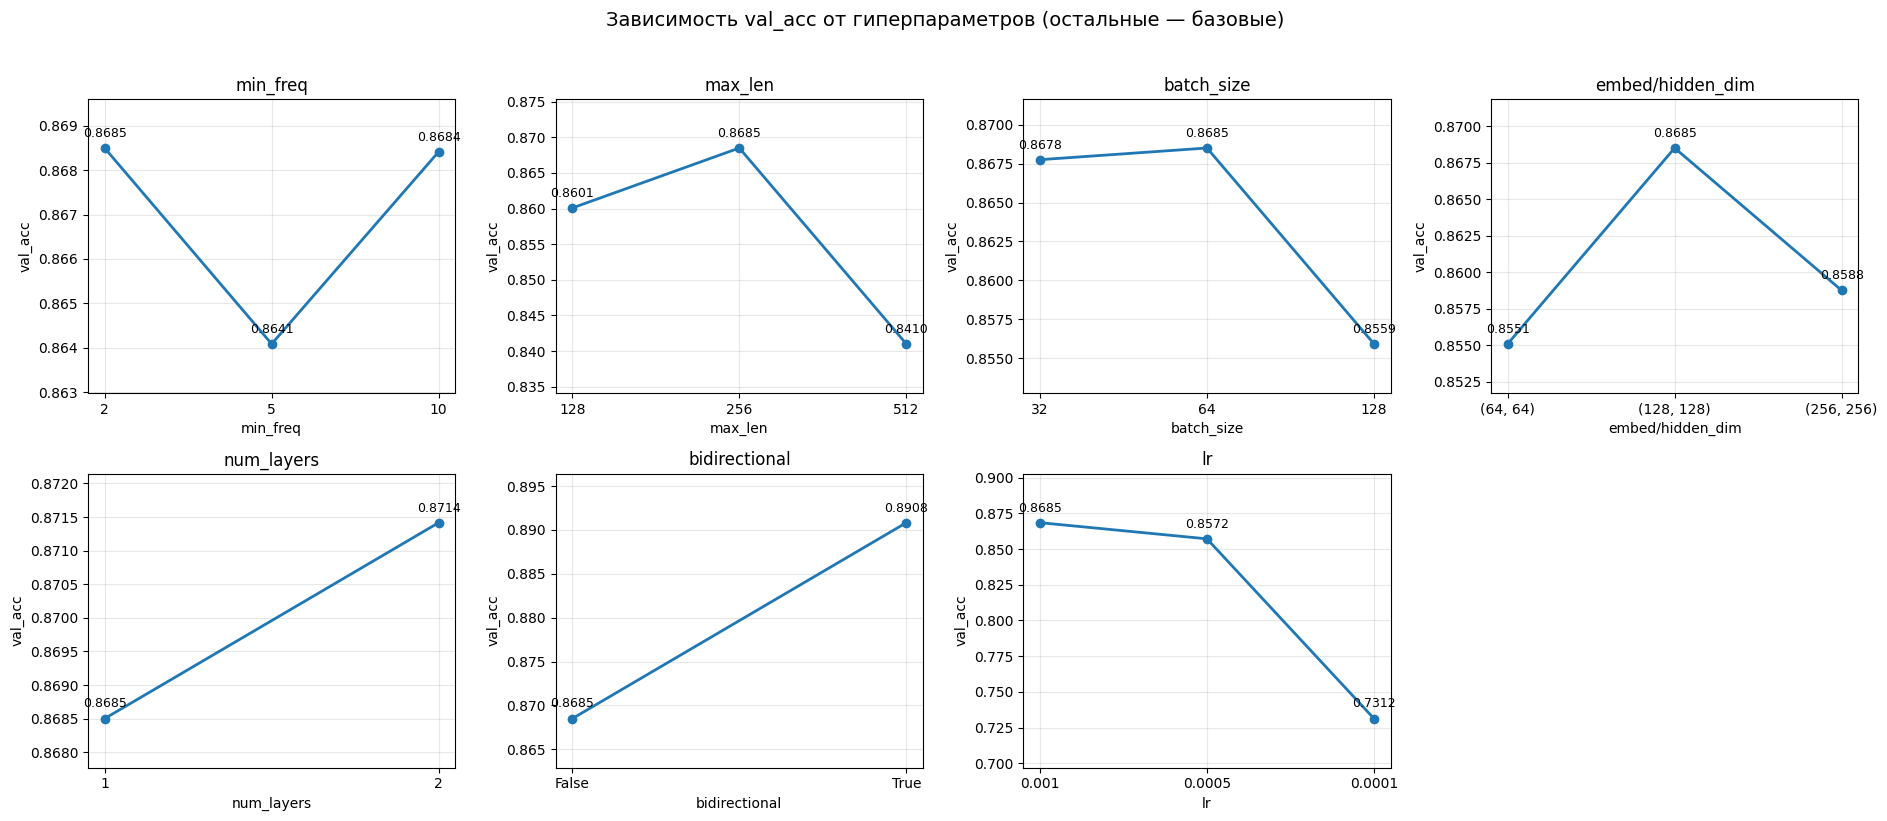

In [ ]:
hps = list(GRID.keys())
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
axes = axes.ravel()

for ax, hp in zip(axes, hps):
    sub = df[df.hyperparam == hp]
    ax.plot(sub['value'], sub['val_acc'], marker='o', linewidth=2)
    for x, y in zip(sub['value'], sub['val_acc']):
        ax.annotate(f"{y:.4f}", (x, y), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=9)
    ax.set_title(hp)
    ax.set_xlabel(hp)
    ax.set_ylabel('val_acc')
    ax.margins(y=0.25)
    ax.grid(alpha=0.3)

axes[-1].axis('off')
plt.suptitle('Зависимость val_acc от гиперпараметров (остальные — базовые)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**небольшой анализ/интерпретация/наблюдения**
*   при bidirectional=True val_acc растёт 0.8685 → 0.8908, а val_loss падает 0.441 → 0.339. Улучшились обе метрики, и параметров добавилось всего ~33k
*   при 1e-4 модель не успела обучиться: val_loss 0.736 и acc 0.731 за 4 эпохи
*    при 128 шагов оптимизации вдвое меньше, и модель недообучается (loss 0.478). Между 32 и 64 разницы по accuracy нет (0.8678 vs 0.8685)
*   embed/hidden_dim: 128 оптимален. 64 не хватает ёмкости (0.8551), а 256 хуже 128 (0.8588) при вдвое большем числе параметров



насколько каждый гиперпараметр меняет `val_acc`

In [ ]:
sens = (df.groupby('hyperparam')['val_acc']
          .agg(min='min', max='max')
          .assign(разброс=lambda d: d['max'] - d['min'])
          .sort_values('разброс', ascending=False)
          .round(4))
display(sens)

best = df.loc[df.groupby('hyperparam')['val_acc'].idxmax(), ['hyperparam', 'value', 'val_acc']]
print("Лучшее значение внутри каждой серии:")
display(best.round(4).reset_index(drop=True))

,min,max,разброс
hyperparam,,,
lr,0.7312,0.8685,0.1373
max_len,0.8410,0.8685,0.0275
bidirectional,0.8685,0.8908,0.0223
embed/hidden_dim,0.8551,0.8685,0.0134
batch_size,0.8559,0.8685,0.0126
min_freq,0.8641,0.8685,0.0044
num_layers,0.8685,0.8714,0.0029


Лучшее значение внутри каждой серии:


,hyperparam,value,val_acc
0,batch_size,64,0.8685
1,bidirectional,True,0.8908
2,embed/hidden_dim,"(128, 128)",0.8685
3,lr,0.001,0.8685
4,max_len,256,0.8685
5,min_freq,2,0.8685
6,num_layers,2,0.8714


# Часть B. Анализ ошибок

Анализируем базовую RNN на тестовой выборке.

Test accuracy (базовая RNN): 0.8679
              precision    recall  f1-score   support

       World     0.8647    0.8816    0.8731      1900
      Sports     0.9131    0.9621    0.9370      1900
    Business     0.8407    0.8053    0.8226      1900
    Sci/Tech     0.8490    0.8226    0.8356      1900

    accuracy                         0.8679      7600
   macro avg     0.8669    0.8679    0.8671      7600
weighted avg     0.8669    0.8679    0.8671      7600



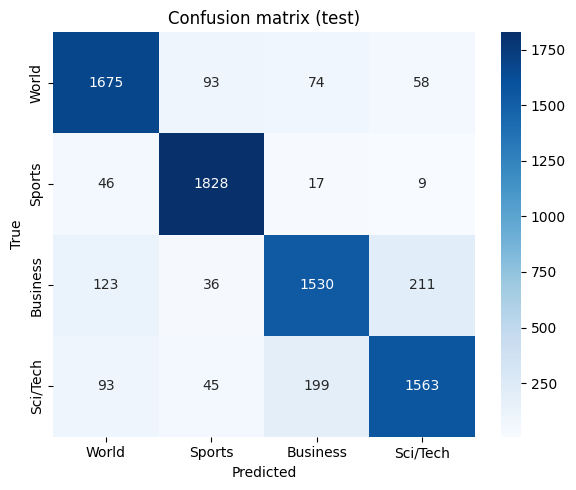

In [ ]:
@torch.no_grad()
def predict(model, vocab, max_len, tokens, labels, batch_size=256):
    loader = make_loader(tokens, labels, vocab, max_len, batch_size)
    _, _, preds, labs = evaluate(model, loader, nn.CrossEntropyLoss())
    return preds, labs


base_model, base_vocab = BASE_RES['model'], BASE_RES['vocab']
test_preds, test_labs = predict(base_model, base_vocab, BASE['max_len'], test_tokens, test_labels)

print(f"Test accuracy (базовая RNN): {(test_preds == test_labs).mean():.4f}")
print(classification_report(test_labs, test_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(test_labs, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test)')
plt.tight_layout(); plt.show()

### 10 примеров, на которых модель ошибается

In [ ]:
n_words = np.array([len(t.split()) for _, t in test_data])
unk_share = np.array([
    np.mean([base_vocab.get(t, UNK_IDX) == UNK_IDX for t in toks]) if toks else 1.0
    for toks in test_tokens
])

err_idx = np.where(test_preds != test_labs)[0]
print(f"Всего ошибок: {len(err_idx)} из {len(test_labs)}\n")

rs = np.random.RandomState(SEED)
sample = rs.choice(err_idx, size=10, replace=False)

for k, i in enumerate(sample, 1):
    print(f"{k}  (test idx {i}) | истина: {CLASS_NAMES[test_labs[i]]} | "
          f"предсказано: {CLASS_NAMES[test_preds[i]]} | слов: {n_words[i]} | <unk>: {unk_share[i]:.0%}")
    print("    " + test_data[i][1][:200].replace("\n", " ") + "\n")

Всего ошибок: 1004 из 7600

1  (test idx 7002) | истина: Sci/Tech | предсказано: Business | слов: 45 | <unk>: 0%
    Human error at EDS to blame for UK outage Electronic Data Systems has admitted that an error by one of its computer operators during a Microsoft Windows upgrade caused 40,000 PCs at the United Kingdom

2  (test idx 4738) | истина: Sci/Tech | предсказано: World | слов: 19 | <unk>: 0%
    Attack prompts Bush website block The re-election website of President Bush is blocking overseas visitors because of "security reasons".

3  (test idx 5151) | истина: Sci/Tech | предсказано: World | слов: 54 | <unk>: 3%
    Contradiction in Terms : How to make beer It's been around for thousands of years. It has been worshiped, reviled, banned, and made the cornerstone of economies. It has helped us celebrate, weep, rela

4  (test idx 3718) | истина: World | предсказано: Sports | слов: 68 | <unk>: 7%
    'Sherlock' Is Bicycling Across Australia PERTH, Australia - A former British soccer p

### Статистика ошибок — чем они отличаются от верных ответов (для проверки гипотез)

In [ ]:
is_err = test_preds != test_labs

stats = pd.DataFrame({
    'ошибки': [n_words[is_err].mean(), np.median(n_words[is_err]), unk_share[is_err].mean()],
    'верные': [n_words[~is_err].mean(), np.median(n_words[~is_err]), unk_share[~is_err].mean()],
}, index=['средняя длина, слов', 'медианная длина, слов', 'средняя доля <unk>']).round(3)
display(stats)

print("Самые частые пары (истина -> предсказание):")
pairs = Counter(zip(test_labs[is_err], test_preds[is_err]))
for (t, p), c in pairs.most_common(6):
    print(f"  {CLASS_NAMES[t]:>9} -> {CLASS_NAMES[p]:<9} {c:>4}  ({c / is_err.sum():.0%} всех ошибок)")

,ошибки,верные
"средняя длина, слов",36.773,37.867
"медианная длина, слов",36.000,37.000
средняя доля <unk>,0.011,0.008


Самые частые пары (истина -> предсказание):
   Business -> Sci/Tech   211  (21% всех ошибок)
   Sci/Tech -> Business   199  (20% всех ошибок)
   Business -> World      123  (12% всех ошибок)
   Sci/Tech -> World       93  (9% всех ошибок)
      World -> Sports      93  (9% всех ошибок)
      World -> Business    74  (7% всех ошибок)


### Гипотезы: почему модель ошибается

*   Пересечение тематики: новости про технологические компании по смыслу одновременно и «бизнес» и «технологии». Лексика в таких темах пересекается: company, shares, deal, sales, software, internet. Модель видит почти одинаковый набор слов, а разметка зависит от того, какой аспект редактор счёл главным.
*   World самый «широкий» класс: политика, экономика стран, конфликты. Бизнес-новость про нефть, санкции или экономику Китая легко читается как World (по сути из-за названия стран новость принимается как за тему World)

### Идеи улучшения

*   Взвешивание/дообучение на парах классов, которые путаются чаще всего (`Business` ↔ `Sci/Tech`), и регуляризация (dropout, early stopping)
*   Не приводить всё к нижнему регистру, либо перейти на subword-токенизацию (BPE/WordPiece), чтобы редкие названия раскладывались на известные части, а не превращались в unkown. Вместе с предыдущей идеей это уменьшает потери на именах компаний, которые и определяют границу Business/Sci/Tech.


# Часть C. Улучшение архитектуры

Сравниваем при **одинаковых** остальных гиперпараметрах (базовая конфигурация, 4 эпохи):
`RNN` (база), `LSTM`, `GRU`, `BiLSTM`, `BiGRU`.

In [ ]:
ARCHS = [

    ('RNN',    'RNN',  False),
    ('LSTM',   'LSTM', False),
    ('GRU',    'GRU',  False),
    ('BiLSTM', 'LSTM', True),
    ('BiGRU',  'GRU',  True),
]

arch_results = {'RNN': BASE_RES}   # базовую RNN уже обучили

for label, rnn_type, bi in ARCHS:
    if label in arch_results:
        continue
    cfg = {**BASE, 'bidirectional': bi}
    arch_results[label] = run_experiment(
        name=label, rnn_type=rnn_type, epochs=EPOCHS,
        return_artifacts=True, **cfg
    )


=== LSTM | vocab=42,506 | params=5,573,380 ===
  epoch 1/4 |  19.7s | train loss 0.5872 acc 0.7753 | val loss 0.3748 acc 0.8825
  epoch 2/4 |  19.8s | train loss 0.3095 acc 0.8955 | val loss 0.2903 acc 0.9043
  epoch 3/4 |  19.5s | train loss 0.2424 acc 0.9188 | val loss 0.2723 acc 0.9137
  epoch 4/4 |  19.3s | train loss 0.2018 acc 0.9316 | val loss 0.2640 acc 0.9184

=== GRU | vocab=42,506 | params=5,540,356 ===
  epoch 1/4 |  19.3s | train loss 0.5532 acc 0.7840 | val loss 0.3241 acc 0.8908
  epoch 2/4 |  19.2s | train loss 0.2781 acc 0.9032 | val loss 0.2640 acc 0.9103
  epoch 3/4 |  19.0s | train loss 0.2179 acc 0.9252 | val loss 0.2462 acc 0.9199
  epoch 4/4 |  18.7s | train loss 0.1816 acc 0.9377 | val loss 0.2467 acc 0.9183

=== BiLSTM | vocab=42,506 | params=5,705,988 ===
  epoch 1/4 |  27.7s | train loss 0.5155 acc 0.8068 | val loss 0.3205 acc 0.8903
  epoch 2/4 |  27.7s | train loss 0.2739 acc 0.9055 | val loss 0.2718 acc 0.9094
  epoch 3/4 |  27.3s | train loss 0.2093 acc 

In [ ]:
rows_c = []
for label, r in arch_results.items():
    t_preds, t_labs = predict(r['model'], r['vocab'], r['max_len'], test_tokens, test_labels)
    r['test_acc'] = float((t_preds == t_labs).mean())
    r['test_preds'] = t_preds
    rows_c.append({
        'модель': label,
        'n_params': r['n_params'],
        'epoch_time_s': round(r['epoch_time_s'], 1),
        'val_loss': round(r['val_loss'], 4),
        'val_acc': round(r['val_acc'], 4),
        'test_acc': round(r['test_acc'], 4),
    })

df_c = pd.DataFrame(rows_c)
df_c.to_csv('experiments_part_C.csv', index=False)
display(df_c.style.hide(axis='index').format({'n_params': '{:,}'}))

модель,n_params,epoch_time_s,val_loss,val_acc,test_acc
RNN,"5,474,308",18.100000,0.441000,0.868500,0.867900
LSTM,"5,573,380",19.600000,0.264000,0.918400,0.917600
GRU,"5,540,356",19.100000,0.246700,0.918300,0.917200
BiLSTM,"5,705,988",27.500000,0.249200,0.919800,0.921600
BiGRU,"5,639,940",26.800000,0.250400,0.919900,0.918300


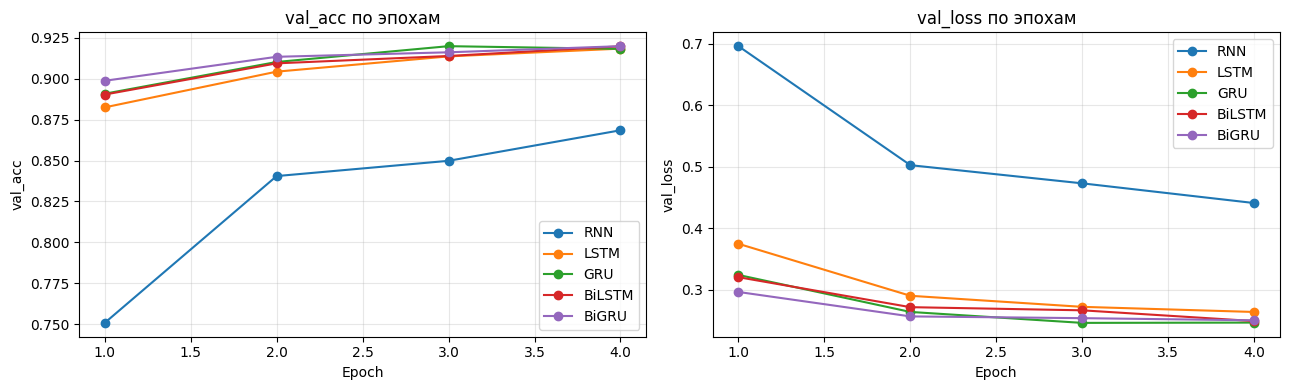

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, r in arch_results.items():
    ep = range(1, len(r['history']['val_acc']) + 1)
    axes[0].plot(ep, r['history']['val_acc'], marker='o', label=label)
    axes[1].plot(ep, r['history']['val_loss'], marker='o', label=label)

axes[0].set_title('val_acc по эпохам');  axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('val_acc')
axes[1].set_title('val_loss по эпохам'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('val_loss')
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Почему LSTM/GRU обычно лучше на длинных последовательностях**

гейтовые модели после первой эпохи почти догоняют то, до чего обычная RNN не дошла за четыре. То есть сигнал от потери доходит до весов и эмбеддингов слов из начала текста, поэтому оптимизация идёт эффективнее. У RNN градиент от конца к началу затухает, и она учится на основном по последним словам.

# Часть D. Мини-исследование: «чем длиннее текст, тем лучше модель его классифицирует»


In [ ]:
df_len = pd.DataFrame({'words': n_words})
for label, r in arch_results.items():
    df_len[label] = (r['test_preds'] == test_labs).astype(int)

bins   = [-1, 50, 100, 200, np.inf]
blabel = ['0–50', '51–100', '101–200', '200+']
df_len['bucket'] = pd.cut(df_len['words'], bins=bins, labels=blabel)

models = list(arch_results.keys())
acc_by_len = df_len.groupby('bucket', observed=False)[models].mean()
cnt_by_len = df_len.groupby('bucket', observed=False).size()

summary = acc_by_len.round(4).copy()
summary.insert(0, 'n', cnt_by_len)
display(summary)

,n,RNN,LSTM,GRU,BiLSTM,BiGRU
bucket,,,,,,
0–50,7109,0.8696,0.9197,0.9187,0.9218,0.9188
51–100,473,0.8457,0.8922,0.9006,0.9197,0.9133
101–200,18,0.7778,0.7778,0.7778,0.8889,0.8333
200+,0,NaN,NaN,NaN,NaN,NaN


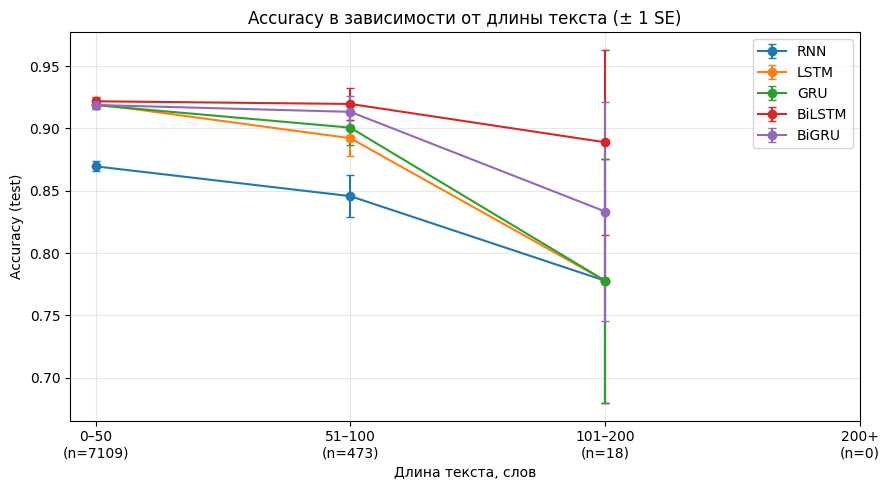

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(blabel))

for label in models:
    p = acc_by_len[label].values
    n = cnt_by_len.values
    se = np.sqrt(p * (1 - p) / np.maximum(n, 1))      # стандартная ошибка доли
    ax.errorbar(x, p, yerr=se, marker='o', capsize=3, label=label)

ax.set_xticks(x)
ax.set_xticklabels([f"{b}\n(n={c})" for b, c in zip(blabel, cnt_by_len.values)])
ax.set_xlabel('Длина текста, слов')
ax.set_ylabel('Accuracy (test)')
ax.set_title('Accuracy в зависимости от длины текста (± 1 SE)')
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### Вывод по части D

Гипотеза «чем длиннее текст, тем лучше модель его классифицирует» на данном датасете не подтверждается: точность не растёт с длиной ни у одной из пяти моделей. Почти весь тест (7109 из 7600 примеров) попал в бин 0-50 слов, где оценки точные. При переходе к бину 51-100 слов RNN, LSTM и GRU почти не теряют, что сопоставимо с их стандартной ошибкой, то есть находится на грани значимости. У BiLSTM и BiGRU заметного снижения в этом бине нет. Бин 101-200 слов содержит всего 18 примеров, поэтому один пример меняет сильно точность. Из-за этого все модели в нём статистически неразличимы, и падение до 0.78 нельзя считать признаком того, что длинные тексты классифицируются хуже. Бин 200+ пуст и информации не несёт. Значит, прямую гипотезу данные не поддерживают, но и противоположную («чем длиннее, тем хуже») они подтвердить не могут. Кроме того, длина здесь смешана с тематикой и источником

# Итоговый отчёт

In [ ]:
print("Часть A: лучшее значение по каждому гиперпараметру")
display(best.round(4).reset_index(drop=True))

print("Часть C: сравнение архитектур")
display(df_c)

Часть A: лучшее значение по каждому гиперпараметру


,hyperparam,value,val_acc
0,batch_size,64,0.8685
1,bidirectional,True,0.8908
2,embed/hidden_dim,"(128, 128)",0.8685
3,lr,0.001,0.8685
4,max_len,256,0.8685
5,min_freq,2,0.8685
6,num_layers,2,0.8714


Часть C: сравнение архитектур


,модель,n_params,epoch_time_s,val_loss,val_acc,test_acc
0,RNN,5474308,18.1,0.4410,0.8685,0.8679
1,LSTM,5573380,19.6,0.2640,0.9184,0.9176
2,GRU,5540356,19.1,0.2467,0.9183,0.9172
3,BiLSTM,5705988,27.5,0.2492,0.9198,0.9216
4,BiGRU,5639940,26.8,0.2504,0.9199,0.9183
